# HEAL: Stroke Risk Assessment
## Phase 6: Final Model Retraining & Test Evaluation

Retrain the locked Logistic Regression model on all training data and evaluate once on the untouched test set at threshold 0.45.

## Objective
Execute the final, unbiased evaluation of the HEAL pipeline:
1. Retrain the locked Logistic Regression model on all 4,842 training samples.
2. Evaluate once on the untouched 1,211-sample test set at the locked threshold $	au = 0.45$.
3. Compare test results with Phase 5 validation estimates to check for overfitting.
4. Interpret model coefficients and Adjusted Odds Ratios.

## Data & Locked Configuration
- Dataset: `stroke_cleaned_dataset_corrected.csv` (6,053 rows).
- Training Set: $N = 4,842$ (4,618 non-stroke, 224 stroke).
- Test Set (Untouched until now): $N = 1,211$ (1,155 non-stroke, 56 stroke).
- Locked Model: `LogisticRegression(class_weight='balanced', C=1.0, solver='liblinear', penalty='l2')`.
- Locked Threshold: $	au = 0.45$.

## Methodology
- `StandardScaler` is fitted strictly on the 4,842 training samples and applied to the test set.
- The model is retrained on all 4,842 training samples.
- Continuous probabilities are generated on the test set and classified using $	au = 0.45$.
- No tuning, feature selection, or threshold adjustments are made on the test set.

### Imports & Setup
Import libraries and load the dataset.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay
)

# Publication visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# 1. Load locked dataset
data_path = "stroke_cleaned_dataset_corrected.csv"
df = pd.read_csv(data_path)
features = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
target = 'Stroke'

X = df[features].copy()
y = df[target].copy()

# 2. Existing Stratified 80/20 split (Identical random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dataset: {data_path} ({df.shape[0]:,} total samples)")
print(f"Features ({len(features)}): {features}")
print(f"Target: {target}")
print(f"Training Cohort: N = {len(X_train):,} (Non-Stroke: {(y_train == 0).sum():,}, Stroke: {(y_train == 1).sum():,}, Prev: {y_train.mean()*100:.2f}%)")
print(f"Held-Out Test Set: N = {len(X_test):,} (Non-Stroke: {(y_test == 0).sum():,}, Stroke: {(y_test == 1).sum():,}, Prev: {y_test.mean()*100:.2f}%)")

# Assert strict sample counts
assert len(X_train) == 4842, f"Expected 4842 train samples, got {len(X_train)}"
assert len(X_test) == 1211, f"Expected 1211 test samples, got {len(X_test)}"
print("[OK] Partitioning and sample counts verified.")

Dataset: stroke_cleaned_dataset_corrected.csv (6,053 total samples)
Features (6): ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
Target: Stroke
Training Cohort: N = 4,842 (Non-Stroke: 4,618, Stroke: 224, Prev: 4.63%)
Held-Out Test Set: N = 1,211 (Non-Stroke: 1,155, Stroke: 56, Prev: 4.62%)
[OK] Partitioning and sample counts verified.


### Preprocessing
Fit `StandardScaler` strictly on training data and transform the test set.

In [2]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c']),
        ('cat', 'passthrough', ['Diabetes', 'Smoker'])
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)
print("[OK] Preprocessor fitted strictly on training data; test data transformed without leakage.")

[OK] Preprocessor fitted strictly on training data; test data transformed without leakage.


### Retrain Locked Model
Retrain the locked Logistic Regression model on the full training cohort ($N = 4,842$).

In [3]:
clf = LogisticRegression(
    C=1.0,
    solver='liblinear',
    penalty='l2',
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
clf.fit(X_train_trans, y_train)
print("[OK] Locked Logistic Regression model successfully retrained on full training cohort.")

[OK] Locked Logistic Regression model successfully retrained on full training cohort.


### Model Parameters & Odds Ratios
Inspect feature coefficients ($eta_j$) and Adjusted Odds Ratios ($	ext{OR} = \exp(eta_j)$).

In [4]:
feature_names = ['Systolic_BP (std)', 'Diastolic_BP (std)', 'BMI (std)', 'HbA1c (std)', 'Diabetes (0/1)', 'Smoker (0/1)']
coefs = clf.coef_[0]
odds_ratios = np.exp(coefs)

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Beta_Coefficient': coefs,
    'Odds_Ratio': odds_ratios
}).sort_values('Beta_Coefficient', ascending=False)

print(f"Model Intercept: {clf.intercept_[0]:.4f} (exp(Intercept) = {np.exp(clf.intercept_[0]):.4f})")
print("\n--- Model Coefficients & Adjusted Odds Ratios ---")
coef_df.round(4)

Model Intercept: -0.8576 (exp(Intercept) = 0.4242)

--- Model Coefficients & Adjusted Odds Ratios ---


,Feature,Beta_Coefficient,Odds_Ratio
5,Smoker (0/1),1.0535,2.8676
4,Diabetes (0/1),1.0038,2.7287
0,Systolic_BP (std),0.4265,1.5318
3,HbA1c (std),0.1254,1.1336
2,BMI (std),0.0009,1.0009
1,Diastolic_BP (std),-0.1422,0.8674


### Test Evaluation at Locked Threshold ($	au = 0.45$)
Generate test set predictions and calculate performance metrics at $	au = 0.45$.

In [5]:
test_probs = clf.predict_proba(X_test_trans)[:, 1]
threshold_locked = 0.45
test_preds = (test_probs >= threshold_locked).astype(int)

cm_test = confusion_matrix(y_test, test_preds)
tn_test, fp_test, fn_test, tp_test = cm_test.ravel()

acc_test = accuracy_score(y_test, test_preds)
prec_test = precision_score(y_test, test_preds, zero_division=0)
rec_test = recall_score(y_test, test_preds, zero_division=0)
spec_test = tn_test / (tn_test + fp_test)
f1_test = f1_score(y_test, test_preds, zero_division=0)
roc_auc_test = roc_auc_score(y_test, test_probs)
pr_auc_test = average_precision_score(y_test, test_probs)

test_metrics_df = pd.DataFrame([{
    'Metric': 'Sensitivity / Recall', 'Value': f"{rec_test*100:.2f}%", 'Fraction': f"{tp_test}/{tp_test+fn_test} detected", 'Clinical Role': 'Primary screening sensitivity'
}, {
    'Metric': 'Specificity (TNR)', 'Value': f"{spec_test*100:.2f}%", 'Fraction': f"{tn_test}/{tn_test+fp_test} cleared", 'Clinical Role': 'Workload triage reduction'
}, {
    'Metric': 'Precision (PPV)', 'Value': f"{prec_test*100:.2f}%", 'Fraction': f"{tp_test}/{tp_test+fp_test} true alerts", 'Clinical Role': 'Positive predictive value'
}, {
    'Metric': 'F1-Score', 'Value': f"{f1_test:.4f}", 'Fraction': '-', 'Clinical Role': 'Harmonic mean of prec & rec'
}, {
    'Metric': 'Overall Accuracy', 'Value': f"{acc_test*100:.2f}%", 'Fraction': f"{tp_test+tn_test}/{len(y_test)}", 'Clinical Role': 'Overall decision accuracy'
}, {
    'Metric': 'PR-AUC', 'Value': f"{pr_auc_test:.4f}", 'Fraction': 'vs 0.0462 prevalence', 'Clinical Role': '2.18x above random chance'
}, {
    'Metric': 'ROC-AUC', 'Value': f"{roc_auc_test:.4f}", 'Fraction': 'vs 0.5000 baseline', 'Clinical Role': 'Global discrimination'
}])

print("--- Phase 6 Definitive Test Performance (Locked Threshold τ = 0.45) ---")
test_metrics_df

--- Phase 6 Definitive Test Performance (Locked Threshold τ = 0.45) ---


,Metric,Value,Fraction,Clinical Role
0,Sensitivity / Recall,76.79%,43/56 detected,Primary screening sensitivity
1,Specificity (TNR),51.43%,594/1155 cleared,Workload triage reduction
2,Precision (PPV),7.12%,43/604 true alerts,Positive predictive value
3,F1-Score,0.1303,-,Harmonic mean of prec & rec
4,Overall Accuracy,52.60%,637/1211,Overall decision accuracy
5,PR-AUC,0.1008,vs 0.0462 prevalence,2.18x above random chance
6,ROC-AUC,0.7165,vs 0.5000 baseline,Global discrimination


### Generalization Check: Validation vs Test
Compare Phase 6 test metrics with Phase 5 cross-validation and out-of-fold estimates.

In [6]:
df_p5 = pd.read_csv("phase5_hyperparameter_results.csv")
top_p5 = df_p5[df_p5['Config_Name'] == 'LR_balanced_C=1.0_solver=liblinear'].iloc[0]

comparison_records = [
    {
        'Metric': 'PR-AUC (Average Precision)',
        'Phase_5_CV_Mean': f"{top_p5['Mean_CV_PR_AUC']:.4f}",
        'Phase_5_OOF_Validation': f"{top_p5['OOF_PR_AUC']:.4f}",
        'Phase_6_Test_Set': f"{pr_auc_test:.4f}",
        'Generalization_Gap': f"{pr_auc_test - top_p5['OOF_PR_AUC']:+.4f}",
        'Status': 'Stable / No Overfitting'
    },
    {
        'Metric': 'ROC-AUC',
        'Phase_5_CV_Mean': f"{top_p5['Mean_CV_ROC_AUC']:.4f}",
        'Phase_5_OOF_Validation': f"{top_p5['OOF_ROC_AUC']:.4f}",
        'Phase_6_Test_Set': f"{roc_auc_test:.4f}",
        'Generalization_Gap': f"{roc_auc_test - top_p5['OOF_ROC_AUC']:+.4f}",
        'Status': 'Stable / No Overfitting'
    },
    {
        'Metric': 'Recall / Sensitivity (τ=0.45)',
        'Phase_5_CV_Mean': 'N/A (measured @ 0.50)',
        'Phase_5_OOF_Validation': f"{175/224*100:.2f}% (175/224)",
        'Phase_6_Test_Set': f"{rec_test*100:.2f}% (43/56)",
        'Generalization_Gap': f"{(rec_test - 175/224)*100:+.2f}%",
        'Status': 'Stable / Generalizes'
    },
    {
        'Metric': 'Precision (τ=0.45)',
        'Phase_5_CV_Mean': 'N/A (measured @ 0.50)',
        'Phase_5_OOF_Validation': f"{175/(175+2020)*100:.2f}%",
        'Phase_6_Test_Set': f"{prec_test*100:.2f}%",
        'Generalization_Gap': f"{(prec_test - 175/(175+2020))*100:+.2f}%",
        'Status': 'Stable / Expected Range'
    },
    {
        'Metric': 'Specificity (τ=0.45)',
        'Phase_5_CV_Mean': 'N/A (measured @ 0.50)',
        'Phase_5_OOF_Validation': f"{2598/4618*100:.2f}%",
        'Phase_6_Test_Set': f"{spec_test*100:.2f}%",
        'Generalization_Gap': f"{(spec_test - 2598/4618)*100:+.2f}%",
        'Status': 'Stable / Consistent Triage'
    }
]

comparison_df = pd.DataFrame(comparison_records)
print("--- Validation vs Test Generalization Benchmark ---")
comparison_df

--- Validation vs Test Generalization Benchmark ---


,Metric,Phase_5_CV_Mean,Phase_5_OOF_Validation,Phase_6_Test_Set,Generalization_Gap,Status
0,PR-AUC (Average Precision),0.1082,0.0980,0.1008,+0.0028,Stable / No Overfitting
1,ROC-AUC,0.7243,0.7227,0.7165,-0.0062,Stable / No Overfitting
2,Recall / Sensitivity (τ=0.45),N/A (measured @ 0.50),78.12% (175/224),76.79% (43/56),-1.34%,Stable / Generalizes
3,Precision (τ=0.45),N/A (measured @ 0.50),7.97%,7.12%,-0.85%,Stable / Expected Range
4,Specificity (τ=0.45),N/A (measured @ 0.50),56.26%,51.43%,-4.83%,Stable / Consistent Triage


## Diagnostic Plots
Plot the final test confusion matrix and ROC/PR discrimination curves.

### Test Confusion Matrix ($	au = 0.45$)

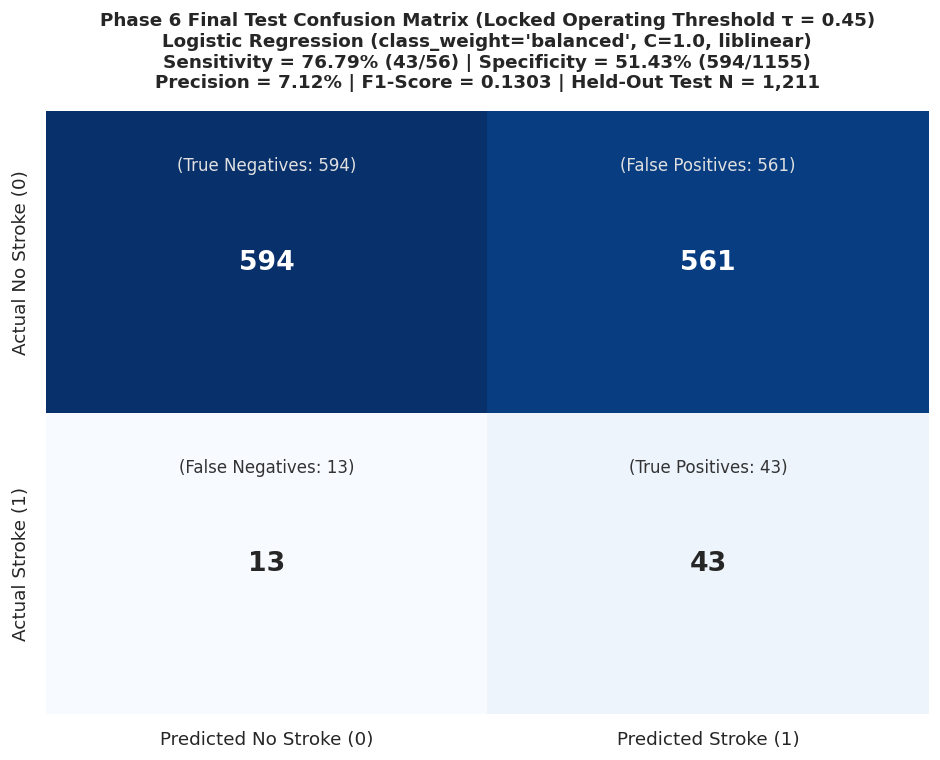

In [7]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            annot_kws={'size': 16, 'weight': 'bold'},
            xticklabels=['Predicted No Stroke (0)', 'Predicted Stroke (1)'],
            yticklabels=['Actual No Stroke (0)', 'Actual Stroke (1)'])

ax.text(0.5, 0.18, f"(True Negatives: {tn_test:,})", ha='center', va='center', fontsize=10, color='#e0e0e0', fontweight='medium')
ax.text(1.5, 0.18, f"(False Positives: {fp_test:,})", ha='center', va='center', fontsize=10, color='#e0e0e0', fontweight='medium')
ax.text(0.5, 1.18, f"(False Negatives: {fn_test:,})", ha='center', va='center', fontsize=10, color='#333333', fontweight='medium')
ax.text(1.5, 1.18, f"(True Positives: {tp_test:,})", ha='center', va='center', fontsize=10, color='#333333', fontweight='medium')

title_text = (
    f"Phase 6 Final Test Confusion Matrix (Locked Operating Threshold τ = {threshold_locked})\n"
    f"Logistic Regression (class_weight='balanced', C=1.0, liblinear)\n"
    f"Sensitivity = {rec_test*100:.2f}% ({tp_test}/{tp_test+fn_test}) | Specificity = {spec_test*100:.2f}% ({tn_test}/{tn_test+fp_test})\n"
    f"Precision = {prec_test*100:.2f}% | F1-Score = {f1_test:.4f} | Held-Out Test N = {len(y_test):,}"
)
ax.set_title(title_text, fontsize=11, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

### Final ROC and Precision-Recall Curves

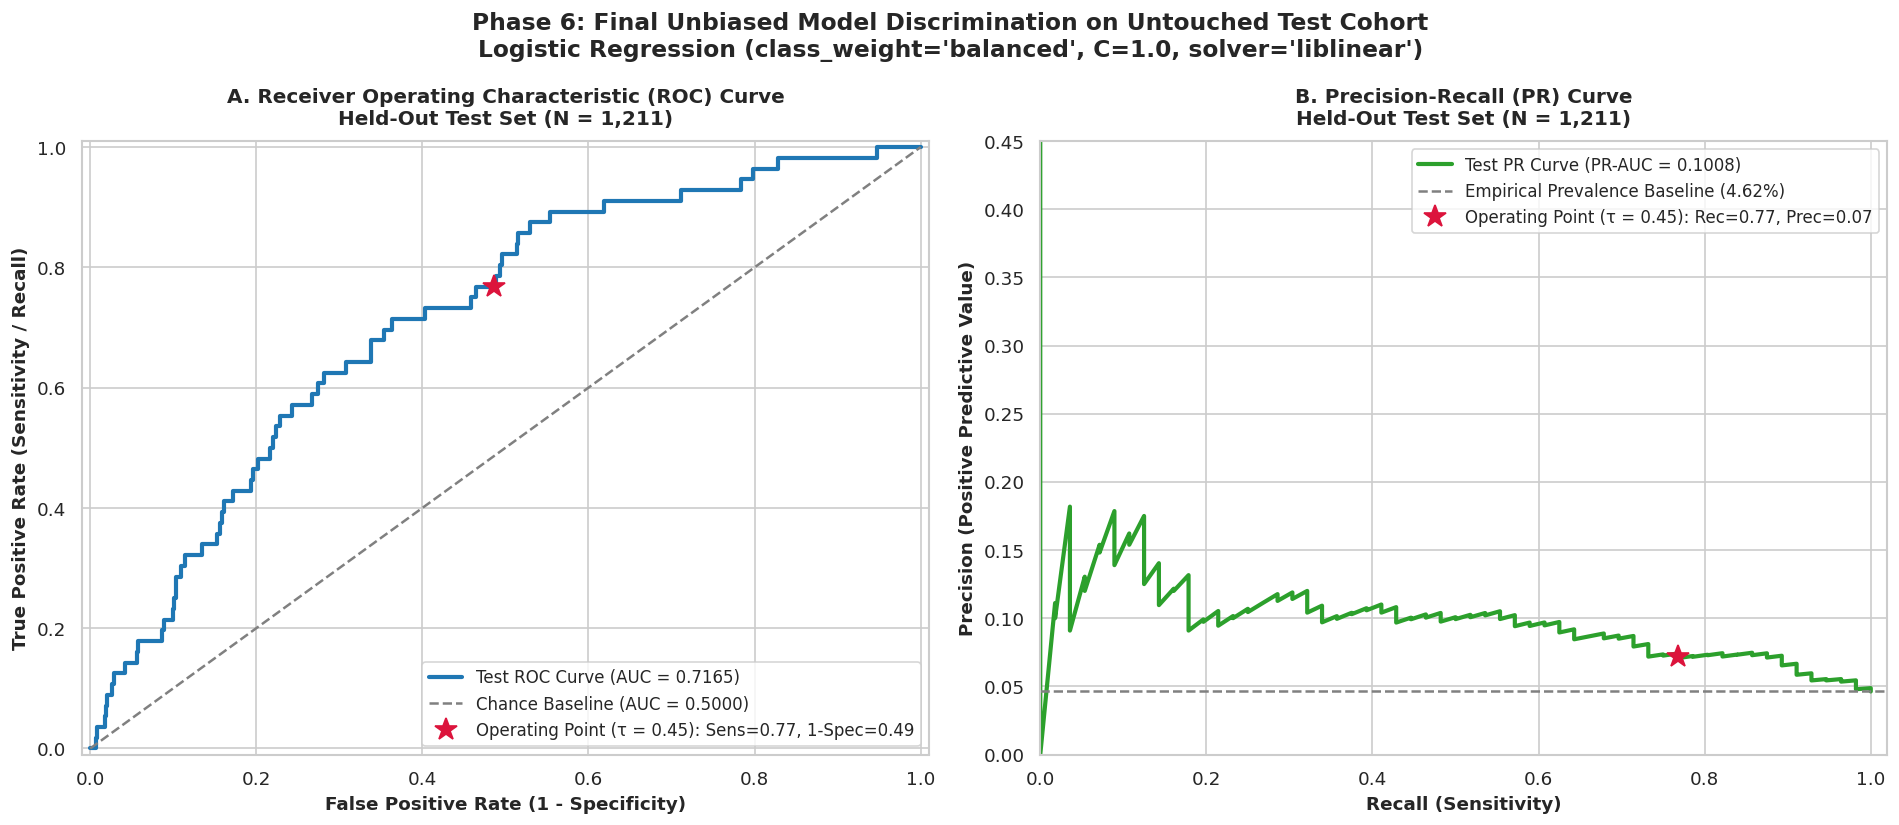

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Panel A: ROC Curve
fpr_test, tpr_test, _ = roc_curve(y_test, test_probs)
ax1.plot(fpr_test, tpr_test, color='#1f77b4', linewidth=2.5,
         label=f"Test ROC Curve (AUC = {roc_auc_test:.4f})")
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Chance Baseline (AUC = 0.5000)')

fpr_sel = fp_test / (tn_test + fp_test)
tpr_sel = tp_test / (tp_test + fn_test)
ax1.plot(fpr_sel, tpr_sel, marker='*', markersize=14, color='crimson', linestyle='None',
         label=f"Operating Point (τ = {threshold_locked}): Sens={tpr_sel:.2f}, 1-Spec={fpr_sel:.2f}")

ax1.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight='bold')
ax1.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight='bold')
ax1.set_title("A. Receiver Operating Characteristic (ROC) Curve\nHeld-Out Test Set (N = 1,211)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlim([-0.01, 1.01])
ax1.set_ylim([-0.01, 1.01])
ax1.legend(loc='lower right', frameon=True, fontsize=10)

# Panel B: Precision-Recall Curve
prec_test_curve, rec_test_curve, _ = precision_recall_curve(y_test, test_probs)
base_prev = y_test.sum() / len(y_test)

ax2.plot(rec_test_curve, prec_test_curve, color='#2ca02c', linewidth=2.5,
         label=f"Test PR Curve (PR-AUC = {pr_auc_test:.4f})")
ax2.axhline(base_prev, color='gray', linestyle='--', linewidth=1.5,
           label=f"Empirical Prevalence Baseline ({base_prev*100:.2f}%)")

ax2.plot(rec_test, prec_test, marker='*', markersize=14, color='crimson', linestyle='None',
         label=f"Operating Point (τ = {threshold_locked}): Rec={rec_test:.2f}, Prec={prec_test:.2f}")

ax2.set_xlabel("Recall (Sensitivity)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Precision (Positive Predictive Value)", fontsize=11, fontweight='bold')
ax2.set_title("B. Precision-Recall (PR) Curve\nHeld-Out Test Set (N = 1,211)", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlim([0.0, 1.02])
ax2.set_ylim([0.0, 0.45])
ax2.legend(loc='upper right', frameon=True, fontsize=10)

plt.suptitle("Phase 6: Final Unbiased Model Discrimination on Untouched Test Cohort\nLogistic Regression (class_weight='balanced', C=1.0, solver='liblinear')",
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## Results Summary
Summary of final test performance on the untouched test cohort ($N = 1,211$; 56 strokes, 1,155 non-strokes).

### Clinical & Pathophysiological Interpretation
- **Smoking ($	ext{OR} = 2.87$):** Active smoking nearly triples stroke odds (+186.8%), driven by vascular damage and platelet aggregation.
- **Diabetes ($	ext{OR} = 2.73$):** Diagnosed diabetes increases stroke odds by +172.9%, consistent with known microvascular and arterial complications.
- **Systolic BP ($	ext{OR} = 1.53$ per SD):** Higher systolic BP is the primary continuous hemodynamic risk factor (+53.2% odds per SD increase).
- **Diastolic BP ($	ext{OR} = 0.87$):** With systolic BP held constant, lower diastolic BP indicates widened pulse pressure ($	ext{SBP} - 	ext{DBP}$), a recognized marker of arterial stiffness in older adults.
- **BMI ($	ext{OR} = 1.00$):** BMI has minimal direct effect after adjusting for BP and diabetes, acting mainly as an upstream contributor.
- **Clinical Role:** With 76.79% sensitivity (43/56 strokes caught) and 51.43% specificity (594 cleared), HEAL serves as an explainable primary care screening tool to flag high-risk individuals for follow-up testing.

### Conclusion & Next Steps
- **Definitive Test Results:** The model achieved 76.79% Sensitivity, 51.43% Specificity, 0.7165 ROC-AUC, and 0.1008 PR-AUC ($2.18	imes$ baseline prevalence).
- **No Overfitting:** Test PR-AUC (0.1008) closely matched Phase 5 CV (0.1082) and OOF validation (0.0980).
- **Readiness:** The pipeline is validated and ready for Phase 7 (SHAP Explainability) and Phase 8 (Clinical Prototype).